Mức nhiễu (σ)   | Intercept (Gốc=4)  | Slope (Gốc=3)   | MSE        | R^2 Score 
σ = 0.5         | 4.0715             | 2.8997          | 0.1634     | 0.9507    
σ = 2.0         | 3.7714             | 2.9682          | 8.2861     | 0.1066    
σ = 5.0         | 4.4416             | 3.1610          | 8.9182     | 0.3807    


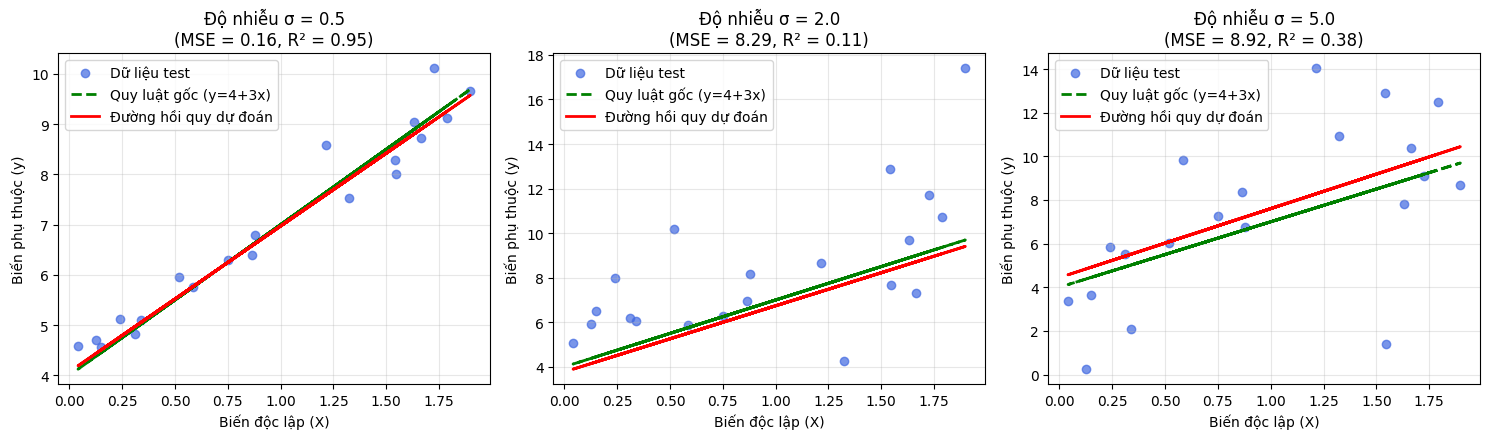

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Cố định biến đầu vào X (100 mẫu) và quy luật gốc: y = 4 + 3x
X = 2 * np.random.rand(100, 1)
y_goc = 4 + 3 * X

# 3 mức độ nhiễu (Độ lệch chuẩn sigma của nhiễu): Thấp (0.5), Trung bình (2.0), Rất cao (5.0)
cac_muc_nhieu = [0.5, 2.0, 5.0]

plt.figure(figsize=(15, 4.5))

print(f"{'Mức nhiễu (σ)':<15} | {'Intercept (Gốc=4)':<18} | {'Slope (Gốc=3)':<15} | {'MSE':<10} | {'R^2 Score':<10}")


for i, sigma in enumerate(cac_muc_nhieu):

    nhieu = sigma * np.random.randn(100, 1)
    y = y_goc + nhieu


    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Huấn luyện và dự đoán
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Tính chỉ số đánh giá
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"σ = {sigma:<11} | {model.intercept_[0]:<18.4f} | {model.coef_[0][0]:<15.4f} | {mse:<10.4f} | {r2:<10.4f}")

    # Vẽ biểu đồ cho từng mức nhiễu
    plt.subplot(1, 3, i + 1)
    plt.scatter(X_test, y_test, color="royalblue", alpha=0.7, label="Dữ liệu test")
    plt.plot(X_test, 4 + 3 * X_test, color="green", linestyle="--", linewidth=2, label="Quy luật gốc (y=4+3x)")
    plt.plot(X_test, y_pred, color="red", linewidth=2, label="Đường hồi quy dự đoán")
    plt.title(f"Độ nhiễu σ = {sigma}\n(MSE = {mse:.2f}, R² = {r2:.2f})")
    plt.xlabel("Biến độc lập (X)")
    plt.ylabel("Biến phụ thuộc (y)")
    plt.legend()
    plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

Ngưỡng (Threshold) | Accuracy   | Precision (Độ chuẩn) | Recall (Độ nhạy) | Báo giả (FP) | Bỏ sót (FN)
Threshold = 0.5    |  76.00%   |           81.82%     |        78.26%    | 8            | 10
Threshold = 0.6    |  76.00%   |           83.33%     |        76.09%    | 7            | 11
Threshold = 0.7    |  73.33%   |           86.11%     |        67.39%    | 5            | 15
Threshold = 0.8    |  73.33%   |           90.62%     |        63.04%    | 3            | 17


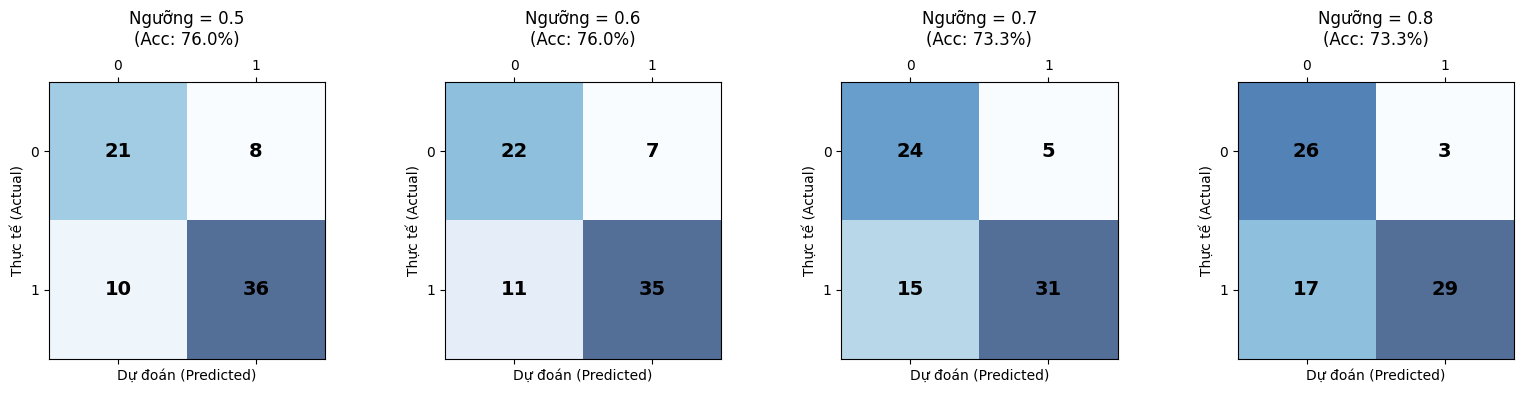

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix


# Ở đây dùng dữ liệu BMI thực tế có vùng giao thoa để các xác suất trải đều từ 0.1 đến 0.9
np.random.seed(42)
BMI = np.random.uniform(15, 40, (300, 1))
xac_suat_goc = 1 / (1 + np.exp(-0.35 * (BMI - 26)))
y = np.random.binomial(1, xac_suat_goc).ravel()

X_train, X_test, y_train, y_test = train_test_split(BMI, y, test_size=0.25, random_state=42)

# Huấn luyện mô hình Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# Lấy mảng xác suất dự đoán cho lớp 1 (P(y = 1 | X)) trên tập kiểm tra
y_prob = model.predict_proba(X_test)[:, 1]

# Danh sách các ngưỡng (Thresholds) cần khảo sát theo đề bài
cac_nguong = [0.5, 0.6, 0.7, 0.8]


print(f"{'Ngưỡng (Threshold)':<18} | {'Accuracy':<10} | {'Precision (Độ chuẩn)':<20} | {'Recall (Độ nhạy)':<16} | {'Báo giả (FP)':<12} | {'Bỏ sót (FN)'}")


fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))

for i, t in enumerate(cac_nguong):
    # Áp dụng ngưỡng t: Nếu xác suất >= t thì gán nhãn 1, ngược lại gán nhãn 0
    y_pred_custom = (y_prob >= t).astype(int)

    acc = accuracy_score(y_test, y_pred_custom)
    prec = precision_score(y_test, y_pred_custom, zero_division=0)
    rec = recall_score(y_test, y_pred_custom, zero_division=0)
    cm = confusion_matrix(y_test, y_pred_custom)
    fp, fn = cm[0][1], cm[1][0]

    print(f"Threshold = {t:<6} | {acc*100:6.2f}%   | {prec*100:15.2f}%     | {rec*100:12.2f}%    | {fp:<12} | {fn}")

    # Vẽ Ma trận nhầm lẫn cho từng ngưỡng
    ax = axes[i]
    ax.matshow(cm, cmap=plt.cm.Blues, alpha=0.7)
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax.text(x=c, y=r, s=cm[r, c], va='center', ha='center', size=14, weight='bold')
    ax.set_title(f"Ngưỡng = {t}\n(Acc: {acc*100:.1f}%)", pad=10)
    ax.set_xlabel("Dự đoán (Predicted)")
    ax.set_ylabel("Thực tế (Actual)")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])


plt.tight_layout()
plt.show()

1. THÔNG TIN BỘ DỮ LIỆU BOSTON HOUSING:

- Kích thước: 506 căn nhà (dòng), 14 thuộc tính (cột)
- 5 dòng dữ liệu đầu tiên:
      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  


2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP KIỂM TRA:
- Hệ số chặn (Intercept):         30.2468
- Mean Squared Error (MSE):       24.2911
- Sai số thực tế trung bình (RMSE): 4.9286 (Tương đương lệch ~$4,929 USD/căn)
- Hệ số xác định (R^2 score):     0.

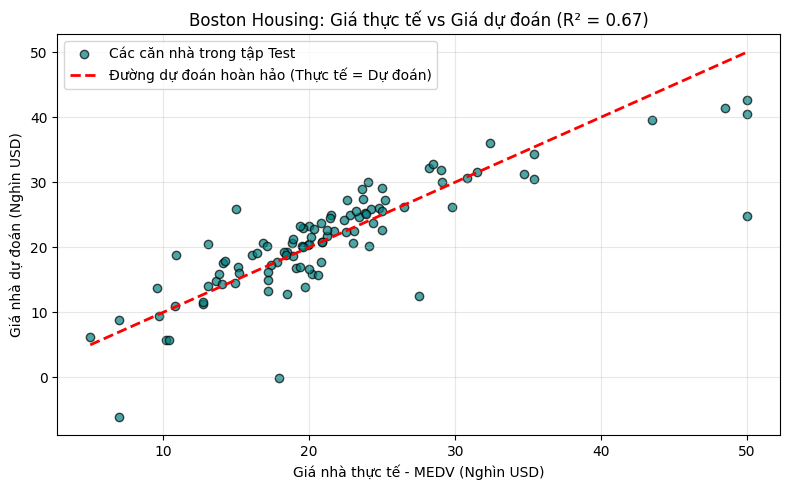

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df_boston = pd.read_csv(url)


print("1. THÔNG TIN BỘ DỮ LIỆU BOSTON HOUSING:\n")

print(f"- Kích thước: {df_boston.shape[0]} căn nhà (dòng), {df_boston.shape[1]} thuộc tính (cột)")
print("- 5 dòng dữ liệu đầu tiên:")
print(df_boston.head())

# Tách 13 biến độc lập (X) và biến phụ thuộc (y là cột 'medv' - Giá nhà trung vị tính bằng $1000)
X = df_boston.drop(columns=['medv'])
y = df_boston['medv']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n")
print("2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP KIỂM TRA:")

print(f"- Hệ số chặn (Intercept):         {model.intercept_:.4f}")
print(f"- Mean Squared Error (MSE):       {mse:.4f}")
print(f"- Sai số thực tế trung bình (RMSE): {rmse:.4f} (Tương đương lệch ~${rmse*1000:,.0f} USD/căn)")
print(f"- Hệ số xác định (R^2 score):     {r2:.4f} (Mô hình giải thích được {r2*100:.2f}% biến động giá nhà)")

# In thêm hệ số góc của các thuộc tính quan trọng nhất để hiểu mô hình
coef_df = pd.DataFrame({'Thuộc tính': X.columns, 'Hệ số (Slope)': model.coef_})
coef_df = coef_df.sort_values(by='Hệ số (Slope)', key=abs, ascending=False)
print("\nTop 5 thuộc tính ảnh hưởng mạnh nhất đến giá nhà Boston:")
print(coef_df.head(5).to_string(index=False))


plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="teal", alpha=0.7, edgecolors="k", label="Các căn nhà trong tập Test")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color="red", linestyle="--", linewidth=2, label="Đường dự đoán hoàn hảo (Thực tế = Dự đoán)")
plt.title(f"Boston Housing: Giá thực tế vs Giá dự đoán (R² = {r2:.2f})", fontsize=12)
plt.xlabel("Giá nhà thực tế - MEDV (Nghìn USD)")
plt.ylabel("Giá nhà dự đoán (Nghìn USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()